# Birds: from BirdNET predictions to observations

This notebook shows how the decision of which BirdNET predictions are real were made. The main code is located in the folder `src/birds/`. The notebook runs it and shows the results. The full explanation for the Tech team is in `reports/02_bird_tech_handoff.md`.

**Question 1:** Using a 99% probability of correctness cutoff, give each clip in `birdnet_predictions` a label in a new `observation` field. 

**Question 2:** The handoff to the Tech team is located in `reports/02_bird_tech_handoff.md`.

BirdNET gives each detection a score between 0 and 1. The score is not a probability. Ornithologists checked a sample of clips. Their answers are used to find, for each species, the score above which predictions are correct 99% of the time.

**Short names used in the text.** Nightjar (*Caprimulgus poliocephalus*),
Oriole (*Oriolus larvatus*), Firefinch (*Lagonosticta senegala*) and
Plover (*Charadrius tricollaris*).

## Setup

Find the folder of the repository and add its `src` folder to the Python path. This lets the notebook import the `birds` and `common` packages in any Jupyter kernel.

In [19]:
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").exists()
)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

Import the libraries and the project code. Set how wide tables can be, and
create the folder for the figures.

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from birds import cli, plots
from birds.thresholds import clopper_pearson_lower
from common.paths import FIGURES, OUTPUTS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
FIGURES.mkdir(parents=True, exist_ok=True)

Run the whole process with one call. `cli.run()` reads the two files,
links checked clips to predictions, fits one curve for each species, finds
the thresholds and labels every prediction. The output below shows the
settings used.

In [21]:
res = cli.run()
cfg = res["cfg"]
pred = res["pred"]
val = res["val"]
links = res["links"]
table = res["table"]
fits = res["fits"]
lab = res["labelled"]
cfg

{'birdnet_version': 'v2.4',
 'target_precision': 0.99,
 'logit_clip': 0.0001,
 'ci_level': 0.95,
 'min_validations': 30,
 'min_negatives_for_curve': 0,
 'bootstrap': {'n': 1000, 'seed': 20240101}}

## Data

Count the predictions, recordings and recorders, and show the dates. Check that each prediction is unique. Then show the scores for each species.

In [22]:
n_rec = pred["begin_path"].nunique()
n_recorders = pred["recorder"].nunique()
print(
    f"{len(pred):,} prediction rows, {n_rec:,} recordings, "
    f"{n_recorders} recorders"
)
start = pred["recording_start"].min().date()
end = pred["recording_start"].max().date()
print("recording dates:", start, "to", end)
is_unique = not pred.duplicated(["begin_path", "selection"]).any()
print("key (begin_path, selection) unique:", is_unique)
pred.groupby("common_name")["confidence"].describe().round(3)

29,491 prediction rows, 1,696 recordings, 43 recorders
recording dates: 2023-06-20 to 2023-07-12
key (begin_path, selection) unique: True


,count,mean,std,min,25%,50%,75%,max
common_name,,,,,,,,
Abyssinian Nightjar,10187.0,0.453,0.328,0.1,0.152,0.322,0.789,1.000
African Black-headed Oriole,18054.0,0.361,0.240,0.1,0.162,0.279,0.513,0.998
Red-billed Firefinch,235.0,0.180,0.114,0.1,0.116,0.137,0.200,0.907
Three-banded Plover,1015.0,0.389,0.270,0.1,0.162,0.286,0.577,1.000


There are 29,491 predictions from 43 recorders over about three weeks. Oriole and Nightjar make up most of them. Firefinch has only
235 predictions, almost all with low scores. The lowest score is 0.1, the minimum used when BirdNET was run.

Compare the checked clips with all predictions, in score groups of 0.1. For each group, it shows how many clips were checked, the share that were correct, and the share of all predictions in that group.

In [23]:
bins = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
v = val.assign(bin=pd.cut(val["confidence"], bins, right=False))
p = pred.assign(bin=pd.cut(pred["confidence"], bins, right=False))
validated = v.pivot_table(
    index="bin",
    columns="commonName",
    values="outcome",
    aggfunc="size",
    observed=False,
)
precision = v.pivot_table(
    index="bin",
    columns="commonName",
    values="outcome",
    aggfunc="mean",
    observed=False,
).round(2)
pred_counts = p.pivot_table(
    index="bin",
    columns="common_name",
    values="confidence",
    aggfunc="size",
    observed=False,
)
share = (pred_counts / p.groupby("common_name").size()).round(3)
comp = pd.concat(
    {
        "validated": validated,
        "precision": precision,
        "share_of_predictions": share,
    },
    axis=1,
)
comp

validated                                                                                precision                                                                       \
commonName Abyssinian Nightjar African Black-headed Oriole Red-billed Firefinch Three-banded Plover Abyssinian Nightjar African Black-headed Oriole Red-billed Firefinch Three-banded Plover   
bin                                                                                                                                                                                            
[0.1, 0.2)                  43                          33                   77                  39                0.33                         1.0                 0.05                1.00   
[0.2, 0.3)                  11                          16                   14                  14                0.73                         1.0                 0.07                0.93   
[0.3, 0.4)                   5                          13                    6                   8                0.80                         1.0                 0.00                1.00   
[0.4, 0.5)                   6                          11                    1                   7                1.00                         1.0                 0.00                1.00   
[0.5, 0.6)                   5                           4                    2                   8                1.00                         1.0                 0.00                1.00   
[0.6, 0.7)                   6                           6                    0                   3                1.00                         1.0                  NaN                1.00   
[0.7, 0.8)                  10                           5                    0                   7                1.00                         1.0                  NaN                1.00   
[0.8, 0.9)                  10                          23                    0                  22                1.00                         1.0                  NaN                1.00   
[0.9, 1.0)                  54                          39                    1                  42                1.00                         1.0                 1.00                1.00   

           share_of_predictions                                                                       
commonName  Abyssinian Nightjar African Black-headed Oriole Red-billed Firefinch Three-banded Plover  
bin                                                                                                   
[0.1, 0.2)                0.362                       0.351                0.749               0.347  
[0.2, 0.3)                0.119                       0.180                0.162               0.167  
[0.3, 0.4)                0.073                       0.118                0.047               0.108  
[0.4, 0.5)                0.055                       0.089                0.009               0.078  
[0.5, 0.6)                0.048                       0.074                0.017               0.064  
[0.6, 0.7)                0.051                       0.060                0.004               0.056  
[0.7, 0.8)                0.048                       0.052                0.009               0.056  
[0.8, 0.9)                0.064                       0.042                0.000               0.050  
[0.9, 1.0)                0.180                       0.033                0.004               0.073

Most checked clips have very low or very high scores. So the share of correct clips in the checks is not the precision of all
predictions. Only the curve, which links score and correctness, can be used.

- Oriole: 150 of 150 correct.
- Plover: 147 of 148 correct.
- Nightjar: the errors are at scores below about 0.4.
- Firefinch: only 6 of 101 correct.

## Linking checked clips to predictions

The file name of a checked clip is `<score>_<n>_<recording>.wav`. It has no prediction id. We link a clip only when exactly one prediction of that species in that recording has the same score. The table counts each case.

In [24]:
links["link_status"].value_counts()

link_status
recording_not_in_predictions    288
unique                          204
ambiguous                        45
no_matching_confidence           14
Name: count, dtype: int64

204 clips link to one prediction. 288 come from recordings that are not in the predictions file. 45 match more than one
prediction. 14 match none. All clips are still used for the curve, which only needs the score and the answer.

Show the clips that were checked twice. We count each of them only once when we fit the curve.

In [25]:
dups = links[links["is_duplicate_review"]].merge(
    val[["filename"]], left_on="val_row", right_index=True
)
dups[["filename", "common_name", "outcome"]]

,filename,common_name,outcome
508,0.885_1_RBS75_20230630_230000.wav,Three-banded Plover,1
512,0.899_2_RBS75_20230628_160000.wav,Three-banded Plover,1


## Fitting the curves

For each species we fit a logistic regression of the answer (1 correct, 0 incorrect) on `logit(score)`, as in Wood & Kahl (2024). The logit scale spreads out the scores close to 1.

The usual logistic regression (GLM) has no solution when all clips are correct (Oriole). It is too confident with only one error (Plover). Firth adds a small correction that always gives a solution, and gives almost the same result when the data are good.

**Finding the threshold:** It is the lowest score from which the curve stays at or above 0.99. We only search inside the range of checked scores, because outside it nobody listened to clips. The table compares Firth with the GLM and shows the uncertainty.

In [26]:
cols = [
    "common_name",
    "n_validated",
    "n_correct",
    "validated_conf_min",
    "validated_conf_max",
    "firth_b0",
    "firth_b1",
    "glm_b0",
    "glm_b1",
    "glm_status",
    "glm_threshold",
    "threshold",
    "threshold_status",
    "conservative_threshold",
    "bootstrap_ci_low",
    "bootstrap_ci_high",
    "bootstrap_share_with_threshold",
    "n_validated_above_threshold",
    "empirical_precision_above_threshold",
    "precision_lower_95_above_threshold",
]
table[cols].set_index("common_name").T

common_name,Abyssinian Nightjar,African Black-headed Oriole,Red-billed Firefinch,Three-banded Plover
n_validated,150,150,101,148
n_correct,117,150,6,147
validated_conf_min,0.102,0.104,0.101,0.102
validated_conf_max,1.0,0.989,0.907,0.994
firth_b0,2.896377,5.054132,-1.450992,4.257824
firth_b1,1.912097,-0.057124,0.870089,0.20961
glm_b0,3.158998,NaN,-1.457779,5.159881
glm_b1,2.07227,NaN,0.942296,0.540013
glm_status,ok,no_variation_in_outcome,ok,ok
glm_threshold,0.666638,NaN,NaN,0.260027


Nightjar 0.709 and Plover 0.833 cross 0.99 inside the checked range. Oriole is above 0.99 everywhere, so its threshold is the lowest checked score, 0.104. Firefinch never reaches 0.99 inside the checked range, so it has no threshold.

The bootstrap range comes from refitting on 1,000 resamples of the checked clips. It is narrow for Oriole, wider for Nightjar (0.50 to 0.87) and very wide for Plover (0.10 to 0.96), because Plover has only one error to learn from.

In [27]:
for r in table.itertuples():
    if np.isfinite(r.threshold):
        print(
            f"When BirdNET predicts {r.common_name} with a score of "
            f"{r.threshold:.3f} or more, we can be 99% sure it is correct."
        )
    else:
        print(f"{r.common_name}: no score gives 99% certainty.")

When BirdNET predicts Abyssinian Nightjar with a score of 0.709 or more, we can be 99% sure it is correct.
When BirdNET predicts African Black-headed Oriole with a score of 0.104 or more, we can be 99% sure it is correct.
Red-billed Firefinch: no score gives 99% certainty.
When BirdNET predicts Three-banded Plover with a score of 0.833 or more, we can be 99% sure it is correct.


Draw one panel for each species: checked clips (green correct, red incorrect), the Firth curve with its 95% band, the GLM curve (dashed), the 0.99 target (dotted) and the threshold (vertical line).

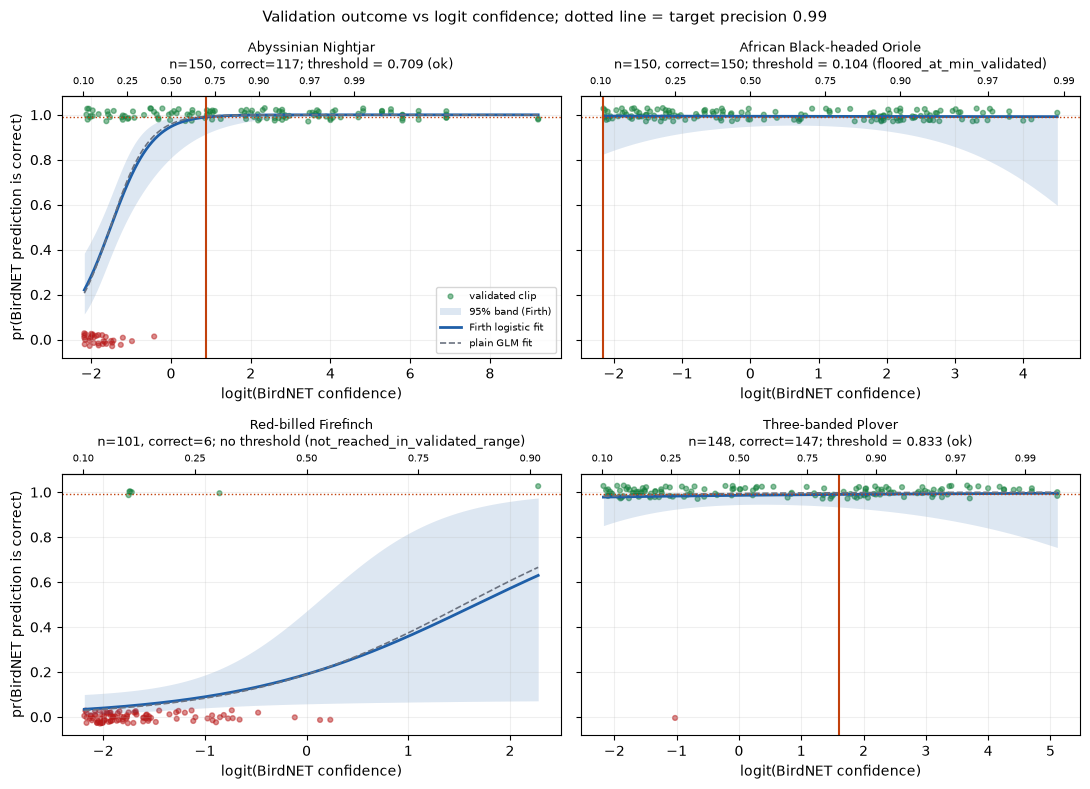

In [28]:
fig = plots.plot_species_curves(
    res["fit_val"],
    table,
    fits,
    cfg,
    FIGURES / "birds_threshold_curves.png",
)
plt.show()

Print the note for each species. The note explains why the threshold was set at the lowest score or not found.

In [29]:
for r in table.itertuples():
    note = r.notes or "threshold inside the validated range"
    print(f"{r.common_name}: {note}")

Abyssinian Nightjar: threshold inside the validated range
African Black-headed Oriole: curve is above 0.99 across the whole validated range; threshold set to the lowest validated score 0.104
Red-billed Firefinch: curve reaches 0.99 only at 0.9990, above the highest validated score 0.907; not extrapolated
Three-banded Plover: threshold inside the validated range


## 4. How much do the choices matter?

Count how many of the 29,491 predictions would become observations with each possible threshold. Here we ignore the answers of the ornithologists, to compare only the thresholds.

In [30]:
def n_obs(species, thr):
    """Count predictions of a species at or above a threshold."""
    c = pred.loc[pred["common_name"] == species, "confidence"]
    return int((c >= thr).sum()) if np.isfinite(thr) else 0


def counts_for(column):
    """Apply n_obs to every species for one threshold column."""
    return {
        r.common_name: n_obs(r.common_name, getattr(r, column))
        for r in table.itertuples()
    }


sens = pd.DataFrame(
    {
        "predictions": pred.groupby("common_name").size(),
        "Firth (chosen)": counts_for("threshold"),
        "plain GLM": counts_for("glm_threshold"),
        "conservative (lower 95% band)": counts_for("conservative_threshold"),
        "bootstrap CI high": counts_for("bootstrap_ci_high"),
    }
)
sens

,predictions,Firth (chosen),plain GLM,conservative (lower 95% band),bootstrap CI high
Abyssinian Nightjar,10187,2931,3147,1313,2058
African Black-headed Oriole,18054,17646,0,0,17469
Red-billed Firefinch,235,0,0,0,1
Three-banded Plover,1015,106,537,0,38


For Nightjar, Firth and the GLM give similar counts (2,931 and 3,147). For Plover the GLM gives about five times more observations than Firth (537 and 106). This is why we recommend more checks for Plover.

How many checks, all correct, are needed to prove a precision of 0.99 directly, with 95% confidence? We use the Clopper Pearson lower bound.

In [31]:
n_needed = next(
    n for n in range(1, 2000) if clopper_pearson_lower(n, n) >= 0.99
)
n_needed

299

We would need 299 correct checks in a row. Oriole has 150, so its threshold depends on the curve, not on a direct proof. More checks for Oriole are recommended.

## 5. Labelling every prediction

Each prediction takes the first rule that applies:

1. Checked as correct: `validated_correct`.
2. Checked as incorrect: `validated_incorrect`.
3. Species has a threshold: `above_threshold` or `below_threshold`.
4. Otherwise: `no_threshold_for_species`.

Count the predictions for each species and status. The column `observation` has the species name when the status is `validated_correct` or `above_threshold`. Otherwise it is empty.

In [32]:
summary = lab.pivot_table(
    index="common_name",
    columns="observation_status",
    values="confidence",
    aggfunc="size",
    fill_value=0,
)
summary["observations"] = lab.groupby("common_name")["observation"].count()
summary["predictions"] = lab.groupby("common_name").size()
summary.loc["Total"] = summary.sum()
summary

observation_status,above_threshold,below_threshold,no_threshold_for_species,validated_correct,validated_incorrect,observations,predictions
common_name,,,,,,,
Abyssinian Nightjar,2887,7208,0,76,16,2963,10187
African Black-headed Oriole,17620,408,0,26,0,17646,18054
Red-billed Firefinch,0,0,207,1,27,1,235
Three-banded Plover,85,874,0,56,0,141,1015
Total,20592,8490,207,159,43,20751,29491


**What we see.** 20,751 of 29,491 predictions are observations. Most are
Oriole. Firefinch has one observation, a clip that an ornithologist
confirmed.

How often does an ornithologist answer change the decision of the
threshold? Compare the two for every checked and linked prediction.

In [33]:
checked = lab[lab["validated_outcome"].notna()]
by_threshold = checked["confidence"] >= checked["threshold_used"]
by_human = checked["validated_outcome"] == 1
changed = checked[by_threshold != by_human]
print(f"{len(changed)} of {len(checked)} checked predictions change")
changed.groupby(["common_name", "observation_status"]).size()

68 of 202 checked predictions change


common_name           observation_status
Abyssinian Nightjar   validated_correct     32
Red-billed Firefinch  validated_correct      1
Three-banded Plover   validated_correct     35
dtype: int64

68 of 202 checked predictions change. All of them are below the threshold but were confirmed as correct, so they become observations. No checked clip above a threshold was marked incorrect.

Draw the scores of all predictions for each species, with the threshold as a vertical line. The title gives the share of predictions at or above the threshold.

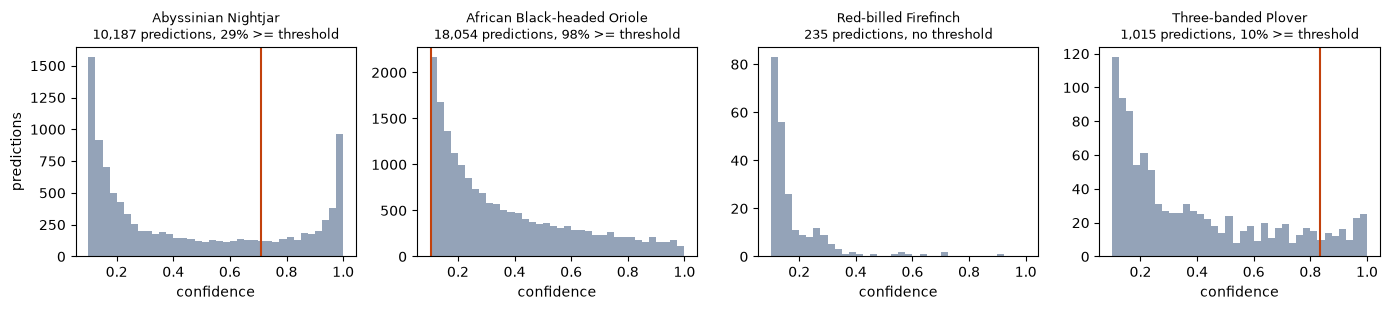

In [34]:
fig = plots.plot_score_distributions(
    pred, table, FIGURES / "birds_score_distributions.png"
)
plt.show()

Count the observations for the 15 recorders with the most observations. These counts are the input for later models of where each species lives.

In [35]:
obs = lab[lab["observation"].notna()]
per_rec = obs.pivot_table(
    index="recorder",
    columns="observation",
    values="confidence",
    aggfunc="size",
    fill_value=0,
)
per_rec = per_rec.assign(total=per_rec.sum(axis=1))
per_rec.sort_values("total", ascending=False).head(15)

observation,Abyssinian Nightjar,African Black-headed Oriole,Red-billed Firefinch,Three-banded Plover,total
recorder,,,,,
RBS58,0,5507,0,0,5507
RBS52,150,2602,0,0,2752
RBS21,277,2124,0,0,2401
RBS14,1160,1175,0,0,2335
RBS38,5,2080,0,0,2085
RBS15,811,724,0,0,1535
RBS75,0,718,0,139,857
RBS51,108,557,0,0,665
RBS55,127,485,1,0,613


For each species, count the recorders and the days with at least one observation.

In [36]:
det = (
    obs.assign(day=obs["clip_start"].dt.date)
    .groupby("observation")[["recorder", "day"]]
    .nunique()
)
det.columns = ["recorders_with_observations", "days_with_observations"]
det

,recorders_with_observations,days_with_observations
observation,,
Abyssinian Nightjar,16,19
African Black-headed Oriole,35,23
Red-billed Firefinch,1,1
Three-banded Plover,3,12


### Check without the ornithologists

If many wrong predictions passed the thresholds, we would see observations at unexpected hours. Oriole is active by day. Nightjar is active at dusk and at night. The figure shows the share of observations for each hour.

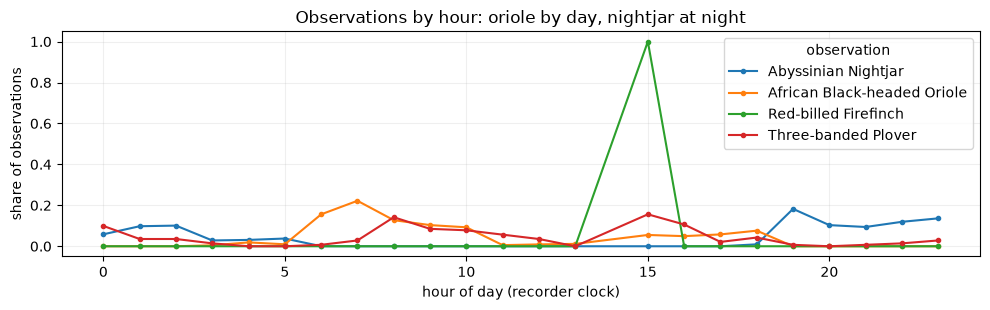

In [37]:
obs_h = obs.assign(hour=obs["clip_start"].dt.hour).pivot_table(
    index="hour",
    columns="observation",
    values="confidence",
    aggfunc="size",
    fill_value=0,
)
fig, ax = plt.subplots(figsize=(10, 3.2))
(obs_h / obs_h.sum()).plot(ax=ax, marker="o", ms=3)
ax.set_ylabel("share of observations")
ax.set_xlabel("hour of day (recorder clock)")
ax.grid(alpha=0.2)
ax.set_title("Observations by hour: oriole by day, nightjar at night")
fig.tight_layout()
fig.savefig(FIGURES / "birds_observations_by_hour.png", dpi=130)
plt.show()

Compute the share of observations recorded at night, from 20:00 to 04:59,
for each species.

In [38]:
night_hours = [h for h in obs_h.index if h < 5 or h >= 20]
night = obs_h.loc[night_hours].sum() / obs_h.sum()
night.round(3).rename("share at night (20:00 to 04:59)")

observation
Abyssinian Nightjar            0.770
African Black-headed Oriole    0.024
Red-billed Firefinch           0.000
Three-banded Plover            0.234
Name: share at night (20:00 to 04:59), dtype: float64

77% of Nightjar observations are at night and only 2% of Oriole observations. This matches how the two species behave, so the thresholds do not let through many wrong predictions.

## Outpus

Write the thresholds, the links and the labelled predictions to `outputs/birds/`. Then read the labelled file again and check that it has one row for each prediction.

In [39]:
cli.write_outputs(res)
out = pd.read_csv(
    OUTPUTS / "birds" / "birdnet_predictions_with_observations.csv"
)
assert len(out) == len(pred) == 29491
print(out.shape)
out.head()

(29491, 20)


,selection,view,channel,begin_time_s,end_time_s,low_freq_hz,high_freq_hz,common_name,species_code,confidence,begin_path,file_offset_s,folder,observation,observation_status,decision_source,threshold_used,threshold_status,p_correct,validated_outcome
0,1,Spectrogram 1,1,889,892,0,15000,African Black-headed Oriole,abhori1,0.6278,Grid2/RBS02/RBS02_20230622_170000.WAV,889,RBS02,African Black-headed Oriole,above_threshold,probabilistic_threshold,0.104000,floored_at_min_validated,0.993467,NaN
1,2,Spectrogram 1,1,1084,1087,0,15000,African Black-headed Oriole,abhori1,0.3217,Grid2/RBS02/RBS02_20230622_170000.WAV,1084,RBS02,African Black-headed Oriole,above_threshold,probabilistic_threshold,0.104000,floored_at_min_validated,0.993921,NaN
2,1,Spectrogram 1,1,3178,3181,0,15000,Abyssinian Nightjar,abynig1,0.1028,Grid2/RBS02/RBS02_20230622_190000.WAV,3178,RBS02,NaN,below_threshold,probabilistic_threshold,0.708564,ok,0.223364,NaN
3,2,Spectrogram 1,1,3574,3577,0,15000,Abyssinian Nightjar,abynig1,0.1456,Grid2/RBS02/RBS02_20230622_190000.WAV,3574,RBS02,NaN,below_threshold,probabilistic_threshold,0.708564,ok,0.380565,NaN
4,1,Spectrogram 1,1,1533,1536,0,15000,Abyssinian Nightjar,abynig1,0.1129,Grid2/RBS02/RBS02_20230623_190000.WAV,1533,RBS02,NaN,below_threshold,probabilistic_threshold,0.708564,ok,0.260124,NaN


Show one example of each status for Nightjar, with the new `observation` field. This is the answer to the question of the brief.

In [40]:
show = [
    "begin_path",
    "selection",
    "confidence",
    "threshold_used",
    "p_correct",
    "validated_outcome",
    "observation_status",
    "observation",
]
nightjar = out[out["common_name"] == "Abyssinian Nightjar"]
examples = nightjar.groupby("observation_status").head(1)
examples[show]

,begin_path,selection,confidence,threshold_used,p_correct,validated_outcome,observation_status,observation
2,Grid2/RBS02/RBS02_20230622_190000.WAV,1,0.1028,0.708564,0.223364,NaN,below_threshold,NaN
242,Grid2/RBS14/RBS14_20230627_190000.WAV,2,0.7539,0.708564,0.993549,NaN,above_threshold,Abyssinian Nightjar
295,Grid2/RBS14/RBS14_20230627_230000.WAV,36,0.7500,0.708564,0.993287,1.0,validated_correct,Abyssinian Nightjar
11705,Grid2/RBS40/RBS40_20230702_180000.WAV,10,0.1391,0.708564,0.356872,0.0,validated_incorrect,NaN


## Decisions

1. Scores are used on the logit scale.
2. Firth logistic regression for every species.
3. Thresholds only inside the checked score range.
4. Flat curve: threshold at the lowest checked score.
5. Ornithologist answers win over the threshold.
6. Clips checked twice count once.

The reasons for each decision are in `reports/01_bird_observations.md`. What the Tech team needs to run this automatically is in `reports/02_bird_tech_handoff.md`.